In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.optimize import fsolve
from scipy.optimize import root_scalar
plt.rcParams["figure.dpi"] = 120

# Prior to Apr 22

looking for critical point

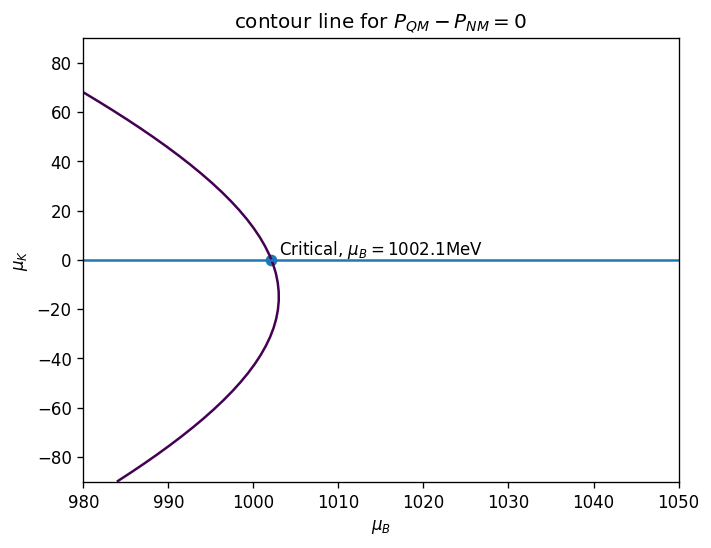

P_{crit} =  36102138.15596604


In [3]:
m_s = 100
m_B = 939
B_one_forth = 170  # 280 for muB/2 in QM
B = B_one_forth**4
muK = np.linspace(-90,90,50)
muB = np.linspace(980, 1050,50)
muK_grid, muB_grid = np.meshgrid(muK, muB)

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

def PQM(muB, muK, B):
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB/3 - muK/2, m_s) - B
    
def PNM(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B)


P_QM = PQM(muB_grid, muK_grid, B) #((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB_grid/3 - muK_grid/2, m_s) - B
P_NM = PNM(muB_grid)

contours = plt.contour(muB_grid, muK_grid, P_QM - P_NM, levels=[0])
#contours = plt.contour(muB_grid, muK_grid, P_QM, levels=[0])
plt.plot(muB, np.zeros(len(muB)))
#plt.plot(1002.1*np.ones(len(muK)), muK)
plt.scatter(1002.1,0)
plt.text(1003, 2, r"Critical, $\mu_B = 1002.1$MeV")
#plt.clabel(contours, inline=True, fontsize=10, fmt="%.1e")
plt.title(r"contour line for $P_{QM} - P_{NM} = 0$")
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.show()

P_crit = PQM(1002.1, 0, B)
print(r"P_{crit} = ", P_crit)

at beta equilibrium

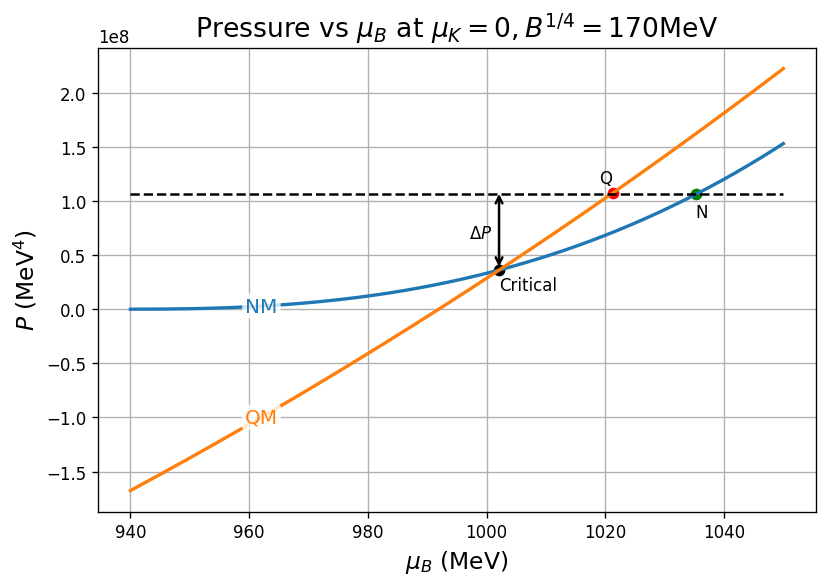

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

def PQM(muB, muK, B):
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB/3 - muK/2, m_s) - B
    
def PNM(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

# Constants
Delta_P = 7e+7
m_B = 939
m_s = 100
B_one_forth = 170  # 280 for muB/2 in QM
B = B_one_forth**4

# mu_B range
muB = np.linspace(940, 1050, 300)

'''
# NM
muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
muQ = -muE
mun = muB
mup = muB + muQ
P_NM = P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

# QM
mu_u = muB / 3
mu_d = muB / 3
mu_s = muB / 3
P_QM = (mu_u**4 + mu_d**4) * 3 / (12 * np.pi**2) + 3 * P_f(mu_s, m_s) - B
'''

# Plot
plt.figure(figsize=(7, 5))
plt.plot(muB, PNM(muB), lw=2, color='tab:blue')
plt.plot(muB, PQM(muB, 0, B), lw=2, color='tab:orange')

# Tight background box
boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB[60], PNM(muB[60]), "NM", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB[60],  PQM(muB[60], 0, B),  "QM", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)
plt.scatter(1002.1, P_crit, c='k') # 3.6e+7
plt.text(1002.1, 0.5*P_crit, r"Critical")
plt.plot(muB, (P_crit + Delta_P)*np.ones(len(muB)), 'k--')
plt.scatter(1021.3, PQM(1021.3, 0, B), c='r')
plt.text(1019, PQM(1020.89,0,B)*1.1, r"Q")
plt.scatter(1035.2, PNM(1035.2), c='g')
plt.text(1035.2, 0.8*PNM(1035.2), r"N")

plt.annotate(
    '', 
    xy=(1002.1, PQM(1002.1, 0, B)), 
    xytext=(1002.1, P_crit+Delta_P*1.05
           ),
    arrowprops=dict(arrowstyle='<->', color='black', lw=1.5),
)
# Optional label for the arrow
plt.text(1002.1-5, (P_crit + Delta_P)/1.5, r'$\Delta P$', va='center')


plt.xlabel(r'$\mu_B$ (MeV)', fontsize=14)
plt.ylabel(r'$P$ (MeV$^4$)', fontsize=14)
plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B^{1/4}=$'+str(B_one_forth)+'MeV', fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

looking down at the dased plane

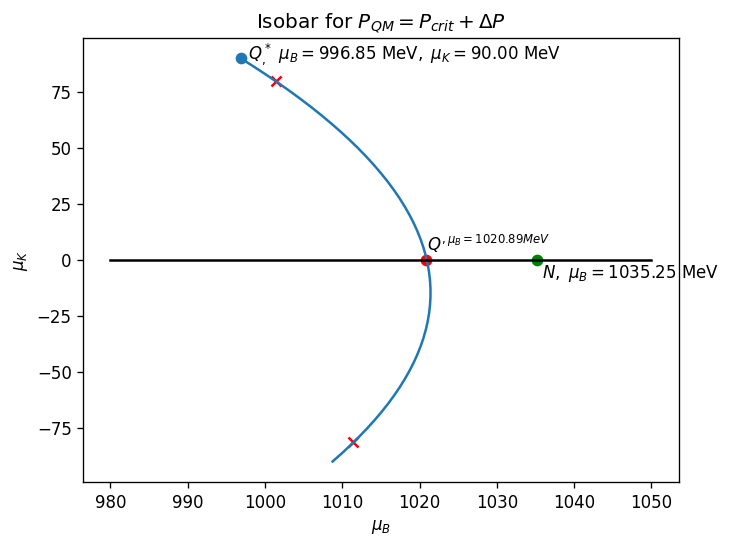

In [10]:
from scipy.signal import argrelextrema
from scipy.optimize import approx_fprime

B = (170)**4
m_s = 100
muK = np.linspace(-90,90,50)
muB = np.linspace(980, 1050,50)
muK_grid, muB_grid = np.meshgrid(muK, muB)
Delta_P = 7e+7

def PQM(muB, muK, B):
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB/3 - muK/2, m_s) - B
    
def PNM(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B)


P_QM = PQM(muB_grid, muK_grid, B) #((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB_grid/3 - muK_grid/2, m_s) - B
P_NM = PNM(muB_grid)

# need to extract the contour curve for later use, such as calculating baryon density and kaon density at each point on the contour
def extract_contour_coords(X, Y, Z, level):
    fig, ax = plt.subplots()
    contour_obj = ax.contour(X, Y, Z, levels=[level])
    # Directly access the paths from the contour object
    paths = []
    for c in contour_obj.get_paths():
        paths.append(c.vertices)
    plt.close(fig)  # Close the plot if you only want data
    if not paths:
        raise RuntimeError(f"No contours found at level {level}")
    return paths[0][:, 0], paths[0][:, 1]

# plot contour
muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
plt.plot(muB_contour_coor, muK_contour_coor)
plt.plot(muB, np.zeros(len(muB)), 'k')

# point Q
#plt.plot(1020.89*np.ones(len(muK)), muK)
plt.scatter(1020.89,0, c='r')
plt.text(1020.9, 4, r"$Q^{, \mu_B = 1020.89 MeV}$")
# rf"$Q,\ \mu_B = {muB.item():2f}\ \mathrm{{MeV}}$"

# point N, taken to be the isobar for NM pressure = P_crit + Delta_P
#plt.contour(muB_grid, muK_grid, P_NM, levels = [P_crit + Delta_P])
#plt.plot(1035.2*np.ones(len(muK)), muK)
PNM_minus_PShift = lambda muB: PNM(muB) - P_crit - Delta_P
muB_N = fsolve(PNM_minus_PShift, 1050)
plt.scatter(1035.2,0, c='g')
plt.text(1035.9, -8, rf"$N,\ \mu_B = {muB_N.item():.2f}\ \mathrm{{MeV}}$")

# point Q star
#plt.plot(1016*np.ones(len(muK)), muK)
plt.scatter(muB_contour_coor[-1],muK_contour_coor[-1])
plt.text(muB_contour_coor[-1]+1, muK_contour_coor[-1], rf"$Q^*_,\ \mu_B = {muB_contour_coor[-1]:.2f}\ \mathrm{{MeV}},\ \mu_K = {muK_contour_coor[-1]:.2f}\ \mathrm{{MeV}}$")

mu_average = []
for i in range(len(muB_contour_coor)):
    muB_Qstar = muB_contour_coor[i]
    muK_Qstar = muK_contour_coor[i]
    Qstar = np.array([muB_Qstar, muK_Qstar])
    grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
    nB_Qstar = grad[0]
    nK_Qstar = grad[1]
    mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
difference = np.abs(np.array(mu_average) - muB_N)
minima_ind = argrelextrema(difference, np.less)[0]

plt.scatter(muB_contour_coor[minima_ind[0]],muK_contour_coor[minima_ind[0]], marker='x', c='r')
plt.scatter(muB_contour_coor[minima_ind[1]],muK_contour_coor[minima_ind[1]], marker='x', c='r')

plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.title(r"Isobar for $P_{QM} = P_{crit} + \Delta P$")
plt.show()

compare $\mu_B^N$ and the average chemical potential at $Q^*$ point: $\overline{\mu}_B^{Q^*} = \mu_B^{Q^*} + \frac{n_K^{Q^*}}{n_B^{Q^*}}\mu_K^{Q^*}$. We see in extreme cases, $\overline{\mu}_B > \mu_B^N$ !!!

In [8]:
# calculate baryon density and kaon density at Q*
from scipy.optimize import approx_fprime

muB_N = 1035.2
muB_Qstar = muB_contour_coor[-1]
muK_Qstar = muK_contour_coor[-1]
Qstar = np.array([muB_Qstar, muK_Qstar])
epsilon = np.sqrt(np.finfo(float).eps) # step size
grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
nB_Qstar = grad[0]
nK_Qstar = grad[1]

mu_average = muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar
print("average chemical potential = ", mu_average, " | chemical potential at point N = ", muB_N)

average chemical potential =  1038.8163245036349  | chemical potential at point N =  1035.2


Text(35, 1035.6, '$\\mu_B^N$')

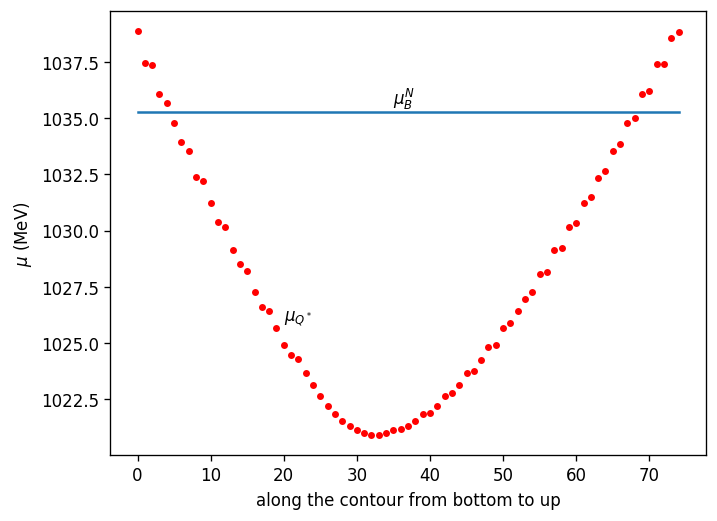

In [108]:
# search for every point on the contour curve and see which Q star the average chemical potential exceeds that for N
epsilon = np.sqrt(np.finfo(float).eps)
mu_average = []

for i in range(len(muB_contour_coor)):
    muB_Qstar = muB_contour_coor[i]
    muK_Qstar = muK_contour_coor[i]
    Qstar = np.array([muB_Qstar, muK_Qstar])
    grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
    nB_Qstar = grad[0]
    nK_Qstar = grad[1]
    mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)

PNM_minus_PShift = lambda muB: PNM(muB) - P_crit - Delta_P
muB_N = fsolve(PNM_minus_PShift, 1050)
difference = np.abs(np.array(mu_average) - muB_N)
minima_ind = argrelextrema(difference, np.less)[0]

plt.scatter([i for i in range(len(mu_average))], mu_average, c='r', s=10)
plt.plot([i for i in range(len(mu_average))], muB_N*np.ones(len(mu_average)))
plt.xlabel("along the contour from bottom to up")
plt.ylabel(r"$\mu$ (MeV)")
plt.text(20, 1026, r"$\mu_{Q^*}$")
plt.text(35, 1035.6, r"$\mu_B^N$")

In [8]:
Delta_P/P_crit

np.float64(1.9389433306578874)

when varying $\Delta P$, see how does the limiting $Q^*$ point move

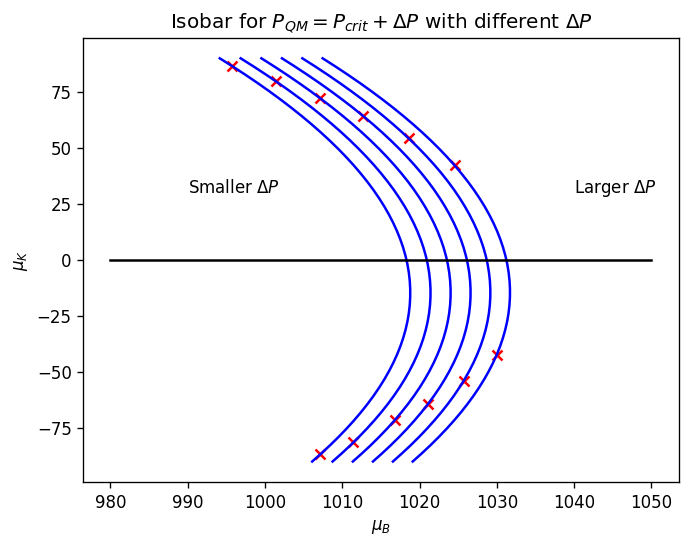

In [109]:
from scipy.signal import argrelextrema

Delta = np.array([6e+7, 7e+7, 8e+7, 9e+7, 1e+8, 1.1e+8]) #P_crit * np.array([0.1, 0.2, 0.3, 0.4, 0.5]) 1.25611875e+8

for Delta_P in Delta:
    muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
    mu_average = []
    for i in range(len(muB_contour_coor)):
        muB_Qstar = muB_contour_coor[i]
        muK_Qstar = muK_contour_coor[i]
        Qstar = np.array([muB_Qstar, muK_Qstar])
        grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
        nB_Qstar = grad[0]
        nK_Qstar = grad[1]
        mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
    difference = np.abs(np.array(mu_average) - muB_N)
    minima_ind = argrelextrema(difference, np.less)[0]

    plt.plot(muB_contour_coor, muK_contour_coor, 'b')
    plt.scatter(muB_contour_coor[minima_ind[0]],muK_contour_coor[minima_ind[0]], marker='x', c='r')
    plt.scatter(muB_contour_coor[minima_ind[1]],muK_contour_coor[minima_ind[1]], marker='x', c='r')

plt.text(1040, 30, r"Larger $\Delta P$")
plt.text(990, 30, r"Smaller $\Delta P$")
plt.plot(muB, np.zeros(len(muB)), 'k')
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.title(r"Isobar for $P_{QM} = P_{crit} + \Delta P$ with different $\Delta P$")    
plt.show()

so based on the current model, the idea that $\overline{\mu}_B < \mu_B^N$ indeed should give a upper limit on how far can $Q^*$ jump, but only relatively far points are excluded; this means we need to take higher order Taylor expansion in the derivation to see the firm constraints

Follow up steps: include electrons in QM, can also include interactions

I've been reading papers, two interesting things to discuss:
* gauge/gravity duality
* nucleation of strangelets in hot environment, like spiral and merger event, and NM to SQM burning in post merger
* uploaded something to overleaf

# Prior to May 9 

$$
v_{N\to Q} \simeq \sqrt{\frac{D_Q}{\tau_Q} \frac{a_{Q^*}^4 + 2\eta_Q a_{Q^*}^2}{2a_N(a_N - a_{Q^*})} }
\;,\quad  v_{N\to Q}(a_{Q^*}=0) = 0
$$

to understand the plot above: 
* smaller $\Delta P$, larger $a_{Q^*}$
* but smaller $\Delta P$ means less violent phase transition, we expect $v_{N\to Q}$ to be smaller; When $\Delta P = 0$ at $P = P_{crit}$, there's no favored phase and phase transition stops: $a_{Q^*} = 0$ and $v_{N\to Q} = 0$
* but $v_{N\to Q}$ increase with $a_{Q^*}$, so there should be something wrong with the plot above

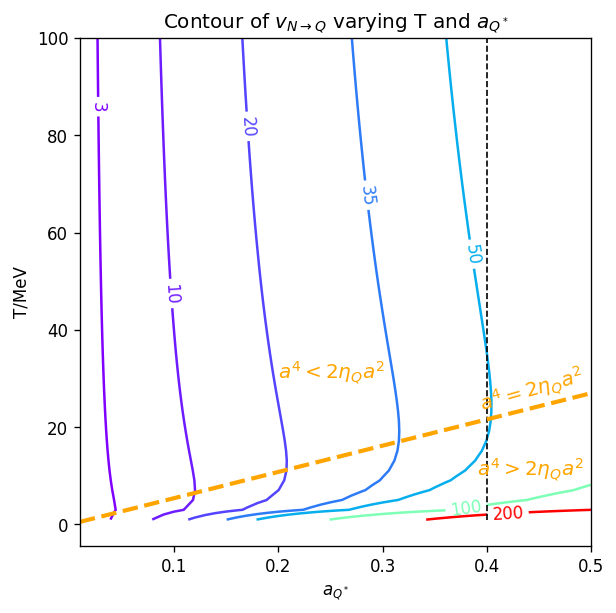

In [140]:
def vNtoQ(aN, muQ, T, aQ):
    # Compute intermediate quantities
    etaQ = (9 * np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300 / muQ)**5)
    DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))
    # Compute v_N->Q
    vNQ = np.sqrt((DQ / tauQ) * ((aQ**4 + 2 * etaQ * aQ**2) / (2 * aN * (aN - aQ)))) * 3e+8
    return vNQ # in (m/s)

aN = 1
muQ = 360
Num = 50
T = np.linspace(1, 100, Num)
aQ = np.linspace(0.01, 0.5, Num)

T_grid, aQ_grid = np.meshgrid(T, aQ)

v = vNtoQ(aN, muQ, T_grid, aQ_grid)  

plt.figure(figsize=[5.5, 5.5])
contours = plt.contour(aQ_grid, T_grid, v, levels=[3, 10, 20, 35, 50, 100, 200], cmap='rainbow')
plt.clabel(contours, inline=True, fontsize=10)

plt.plot(0.4*np.ones(Num), T, 'k--', linewidth=1)

y_values = (np.sqrt(2) * muQ * aQ) / (3 * np.pi)  # T values corresponding to aQ

plt.plot(aQ, y_values, linestyle='--', lw=2.5, color='orange')
x_text = 0.39
y_text = (np.sqrt(2) * muQ * x_text) / (3 * np.pi)  + 1
plt.text(x_text, y_text, r"$a^4 = 2\eta_Q a^2$", fontsize=12, color='orange',
         rotation=16, verticalalignment='bottom')

plt.title(r"Contour of $v_{N\to Q}$ varying T and $a_{Q^*}$")
plt.xlabel(r"$a_{Q^*}$")
plt.ylabel("T/MeV")
#plt.colorbar(label=r'$v_{N\to Q}$/ (m/s)')

plt.text(0.2, 30, r"$a^4<2\eta_Q a^2$", fontsize=12, color='orange')
plt.text(0.39, 10, r"$a^4>2\eta_Q a^2$", fontsize=12, color='orange')

plt.show()

I made a mistake: I didn't change $\Delta P$ when calculating $\mu_B^N$; well because I ploted that on Friday morning in a rush. When corrected, I found the following result:

In [12]:
# this code calculates aQstar 
from scipy.optimize import approx_fprime

def aQstar_and_other_stuff(muB, muK, P_crit, Delta_P):  # the muB should be understood as muB_Qstar, and same for muK
    # calculate nB_Qstar, nK_Qstar using partial derivitives
    Qstar = np.array([muB, muK])
    grad_Qstar = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]

    # solve for muB_Q
    PQM_at_Q = lambda x: PQM(x, 0, B = (170)**4) - P_crit - Delta_P
    muB_Q = fsolve(PQM_at_Q, 1050)[0]  # 1050 is the starting point of numerical root finding

    # calculate nB_Q and nK_Q using partial derivitives
    Q = np.array([muB_Q, 0])  # the point Q
    grad_Q = approx_fprime(Q, PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]

    return (nK_Qstar - nK_Q)/nB_Q , nB_Q, muB_Q


aQstar_and_other_stuff(996.85, 90.00, P_crit, Delta_P)

(np.float64(0.4106179282480219),
 np.float64(3611552.0),
 np.float64(1002.1553822866703))

we should always focus on the upper branch, since in NM to SQM transition, $\mu_K = \mu_d - \mu_s \geq 300MeV - 100MeV >0$ always holds. When plotting, I plotted the lower branch, as a nice way to display $a_{Q^*}^{max} = \sqrt{\frac{2\Delta\mu_B\chi_K^Q}{n_Q}}$ without making things too cramped

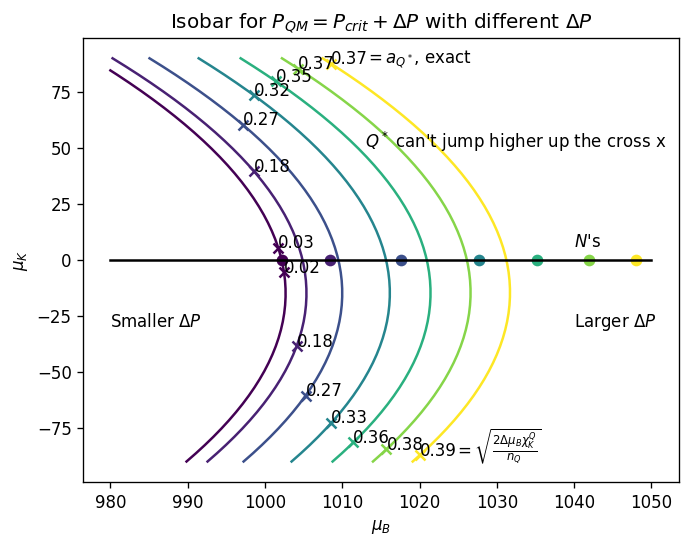

In [13]:
from scipy.signal import argrelextrema
from scipy.optimize import fsolve
import numdifftools as nd
from matplotlib import colormaps
cmap = colormaps['viridis']

Delta = np.array([2e+5, 1e+7, 2.7e+7, 5e+7, 7e+7, 9e+7, 1.1e+8]) #P_crit * np.array([0.1, 0.2, 0.3, 0.4, 0.5])

for Delta_P in Delta:
    muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
    mu_average = []
    for i in range(len(muB_contour_coor)):
        muB_Qstar = muB_contour_coor[i]
        muK_Qstar = muK_contour_coor[i]
        Qstar = np.array([muB_Qstar, muK_Qstar])
        grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
        nB_Qstar = grad[0]
        nK_Qstar = grad[1]
        mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
    PNM_minus_PShift = lambda muB: PNM(muB) - P_crit - Delta_P
    muB_N = fsolve(PNM_minus_PShift, 1050)  # 1050 is the starting point of numerical root finding
    difference = np.abs(np.array(mu_average) - muB_N)
    minima_ind = argrelextrema(difference, np.less)[0]  # this is where the cross is (the index) along the contour line

    muB_Qstar_down = muB_contour_coor[minima_ind[0]]
    muK_Qstar_down = muK_contour_coor[minima_ind[0]]
    muB_Qstar_up = muB_contour_coor[minima_ind[1]]
    muK_Qstar_up = muK_contour_coor[minima_ind[1]]
    
    a_Q_star, nBQ, muBQ = aQstar_and_other_stuff(muB_Qstar_up, muK_Qstar_up, P_crit, Delta_P) # should only use upper value

    # the following calculates a_Q_star_max using the analytical approximation from taylor expansion
    PQM_at_Q = lambda x: PQM(muBQ, x, B = (170)**4) - P_crit - Delta_P
    d2f = nd.Derivative(PQM_at_Q, n=2)
    chiK_Q = d2f(0)
    a_Q_star_max = np.sqrt((2 * (muB_N - muBQ) * chiK_Q) / nBQ)[0]

    # plotting the crosses and the corresponding exact aQstar (on upper branch) and analytical aQstar (on down branch)
    col = cmap(Delta_P/Delta[-1])
    plt.plot(muB_contour_coor, muK_contour_coor, color = col)
    plt.scatter(muB_Qstar_down,muK_Qstar_down, marker='x', color=col)
    plt.scatter(muB_Qstar_up,muK_Qstar_up, marker='x', color=col)
    plt.text(muB_Qstar_up,muK_Qstar_up, f"{a_Q_star:.2f}")
    plt.text(muB_Qstar_down,muK_Qstar_down, f"{a_Q_star_max:.2f}")
    plt.scatter(muB_N, 0, color=col)
    

plt.text(1040, -30, r"Larger $\Delta P$")
plt.text(980, -30, r"Smaller $\Delta P$")
plt.text(1013, 50, r"$Q^*$ can't jump higher up the cross x")
plt.text(1013, 88, r"$=a_{Q^*}$, exact")
plt.text(1024.5, -87.5, r"$=\sqrt{\frac{2\Delta\mu_B\chi_K^Q}{n_Q}}$")
plt.text(1040, 6, r"$N$'s")
plt.plot(muB, np.zeros(len(muB)), 'k')
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.title(r"Isobar for $P_{QM} = P_{crit} + \Delta P$ with different $\Delta P$") 
plt.show()

### expand the taylor series to higher orders to see if we get an analytical result, well...

* checked the math of Eq.(38)
* it's not that we didn't expand to higher enough orders
* the new plot above justifies that we only need to expand to lowest order
* it's that we weren't careful enough while doing the first order
* not correct to assume that $n_B^{Q^*} \simeq n_B^{Q}$ and $n_K^{Q^*} \simeq n_K^{Q}$

$$
\mu_B^N - \mu_B^Q > \left(\frac{n_K^{Q^*}}{n_B^{Q^*}} - \frac{n_K^{Q}}{n_B^{Q}}\right)\mu_K^{Q^*} - \frac{\chi_K^Q}{2 n_B^Q}(\mu_K^{Q^*})^2  =  \left(\frac{n_K^{Q} + \chi_K^Q\mu_K^{Q^*}}{n_B^{Q} + \chi_B^Q\Delta\mu_B} - \frac{n_K^{Q}}{n_B^{Q}}\right)\mu_K^{Q^*} - \frac{\chi_K^Q}{2 n_B^Q}(\mu_K^{Q^*})^2
$$

due to the shape of the isobar at $Q$, we can assume $\mu_K^{Q^*}\gg\Delta \mu_B$, so we can ignore the term $\chi_B^Q\Delta\mu_B$, and get
$$
\mu_B^N - \mu_B^Q > \left(\frac{n_K^{Q} + \chi_K^Q\mu_K^{Q^*}}{n_B^{Q}} - \frac{n_K^{Q}}{n_B^{Q}}\right)\mu_K^{Q^*} - \frac{\chi_K^Q}{2 n_B^Q}(\mu_K^{Q^*})^2 = \left(\frac{\chi_K^Q\mu_K^{Q^*}}{n_B^{Q}} \right)\mu_K^{Q^*} - \frac{\chi_K^Q}{2 n_B^Q}(\mu_K^{Q^*})^2 = \frac{\chi_K^Q}{2 n_B^Q}(\mu_K^{Q^*})^2
$$

so surprisingly, Eq.(38) IS correct, it's just the two mistakes "corrected" each other

### things to do next?

* look for more stuff that this toy model can tell us? --- still thinking how can we play with this model further
* learn relativistic mean field theory and finite temperature QFT during the summer since there's a lot of time; my plan is to read books and bring questions to weekly discussions
* about surviving in physics academia, I realized this is important, so is it alright to spare some time in our meeting to discuss this so us new beginners get prepared 

# Free quark model

$$
\begin{aligned}
P_u & = \frac{\mu_u^4}{4\pi^2}\\
P_d & = \frac{\mu_d^4}{4\pi^2}\\
P_e & = \frac{\mu_e^4}{12\pi^2}\\
P_s & = \frac{1}{4\pi^2}\left[ \mu_s(\mu_s^2 - m^2)^{1/2}\left(\mu_s^2 - \frac{5}{2}m^2\right)\frac{3}{2}m^4\ln\frac{\mu_s + (\mu_s^2 - m^2)^{1/2}}{m}\right]\\
\end{aligned}
$$

In [3]:
def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ( (2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m) )/(24*np.pi**2)

def n_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return k_F**3 / (3 * np.pi**2)

In [13]:
def charge_neutrality(mu_u, mu, ms):
    mu_d = mu
    mu_s = mu
    mu_e = mu - mu_u 
    lhs = (2/3) * 3*n_f(mu_u, 0) 
    rhs = (1/3) * 3*n_f(mu_u, 0) + (1/3) * 3*n_f(mu_s, ms) + n_f(mu_e, 0)
    return lhs - rhs

def solve_mu_u(mu, ms):
    # Choose a reasonable search bracket for mu_u
    # Must be mu_u > 0, and large enough to contain all real roots
    bracket = [1, 1000]  # MeV scale
    try:
        sol = root_scalar(charge_neutrality, args=(mu, ms), method='brentq', bracket=bracket)
        if sol.converged:
            return sol.root
        else:
            return None
    except ValueError:
        # No root in the bracket or function doesn't change sign
        return None

start = time.time()
x = solve_mu_u(mu = 300, ms = 100)
end = time.time()
print(x, end - start)

282.8636781760007 0.0003161430358886719


In [19]:
import numpy as np
from scipy.optimize import root_scalar

# P_f and n_f as given
def P_f(mu, m):
    if mu <= m:
        return 0
    k_F = np.sqrt(mu**2 - m**2)
    if m == 0:
        return mu**4 / (12 * np.pi**2)
    log_arg = (k_F + mu) / m
    if log_arg <= 0:
        return 0
    return ((2 * k_F**3 - 3 * m**2 * k_F) * mu + 3 * m**4 * np.log(log_arg)) / (24 * np.pi**2)

def n_f(mu, m):
    if mu < m:
        return 0
    k_F = np.sqrt(mu**2 - m**2)
    return k_F**3 / (3 * np.pi**2)

# Charge neutrality equation for mu_u
def charge_neutrality(mu_u, mu, ms):
    mu_d = mu
    mu_s = mu
    mu_e = mu - mu_u 
    lhs = (2/3) * 3 * n_f(mu_u, 0) 
    rhs = (1/3) * 3 * n_f(mu_u, 0) + (1/3) * 3 * n_f(mu_s, ms) + n_f(mu_e, 0)
    return lhs - rhs

# Solve for mu_u given mu and ms
def solve_mu_u(mu, ms):
    lower = 1
    upper = mu - 1e-3
    if upper <= lower:
        return None
    try:
        sol = root_scalar(charge_neutrality, args=(mu, ms), method='brentq', bracket=[lower, upper])
        if sol.converged:
            return sol.root
    except (ValueError, RuntimeError):
        pass
    return None

# Solve for mu given B and m (ms)
def solve_mu(B, ms):
    def equation(mu):
        mu_u = solve_mu_u(mu, ms)
        if mu_u is None or mu <= ms or mu <= 0:
            return 1e30  # invalid guess or out of domain

        mu_e = mu - mu_u
        try:
            total = (
                3 * P_f(mu_u, 0) +
                3 * P_f(mu, 0) +
                3 * P_f(mu, ms) +
                P_f(mu_e, 0)
            )
            return total - B
        except (ValueError, ZeroDivisionError, RuntimeWarning):
            return 1e30

    try:
        sol = root_scalar(equation, bracket=[ms + 1, 2000], method='brentq')
        if sol.converged:
            mu = sol.root
            mu_u = solve_mu_u(mu, ms)
            return mu, mu_u
        else:
            return None, None
    except ValueError:
        return None, None

# Example usage:
B = (145**4)  # MeV^4
ms = 150      # MeV
mu, mu_u = solve_mu(B, ms)
print("μ =", mu)
print("μ_u =", mu_u)

μ = 304.3001177295874
μ_u = 265.0485851207226


In [21]:
def E_by_A(B, m):
    mu_tot, mu_u = solve_mu(B, m)
    mu_d = mu_tot
    mu_s = mu_tot
    mu_e = mu_tot - mu_u
    n_u = 3*n_f(mu_u, 0)
    n_d = 3*n_f(mu_d, 0)
    n_s = 3*n_f(mu_s, m)
    n_e = n_f(mu_e, 0)
    return (n_u*mu_u + n_d*mu_d + n_s*mu_s + n_e*mu_e)/((n_u + n_d + n_s)/3)

E_by_A(B=(155)**4, m=100)

np.float64(908.7302688364058)

## Plot the contour

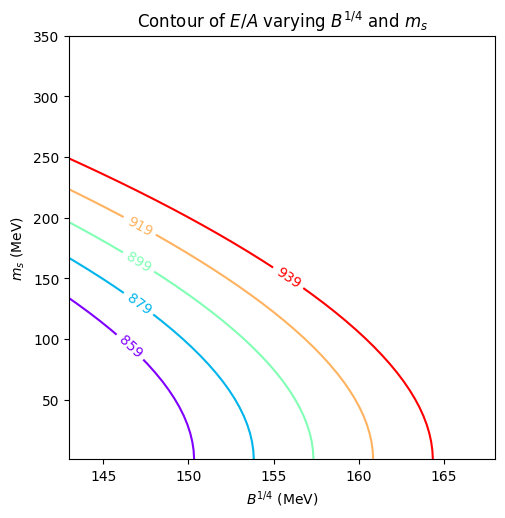

In [38]:
Num = 50
B_qua = np.linspace(143, 168, Num)
m = np.linspace(1, 350, Num)

B_qua_grid, m_grid = np.meshgrid(B_qua, m)
E_A = np.zeros([Num, Num])

for i in range(Num):
    for j in range(Num):
        E_A[i,j] = E_by_A(B_qua_grid[i,j]**4, m_grid[i,j])

plt.figure(figsize=[5.5, 5.5])
contours = plt.contour(B_qua_grid, m_grid, E_A, levels=[859, 879, 899, 919, 939], cmap='rainbow')
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $E/A$ varying $B^{1/4}$ and $m_s$")
plt.xlabel(r"$B^{1/4}$ (MeV)")
plt.ylabel(r"$m_s$ (MeV)")
#plt.colorbar(label=r'$v_{N\to Q}$/ (m/s)')


#downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
#plt.savefig(os.path.join(downloads_path, "tst.png"), dpi=300)  # Increase DPI as needed

plt.show()